In [60]:
import numpy as np

# Фіксація генератора випадкових чисел за номером варіанта (1)
rng = np.random.default_rng(1)

lam = 0.20
true_mean = 1 / lam  # Теоретичне середнє = 5.0

print(f"Теоретичне математичне сподівання E[X]: {true_mean}\n")

# Перевірка для різних n
for n in [5, 50, 500, 20_000]:
    sample = rng.exponential(scale=1 / lam, size=n)
    sample_mean = sample.mean()
    abs_diff = abs(sample_mean - true_mean)
    print(f"n = {n:5d} | Вибіркове середнє: {sample_mean:.4f} | Абсолютна різниця: {abs_diff:.4f}")

Теоретичне математичне сподівання E[X]: 5.0

n =     5 | Вибіркове середнє: 7.2387 | Абсолютна різниця: 2.2387
n =    50 | Вибіркове середнє: 5.5810 | Абсолютна різниця: 0.5810
n =   500 | Вибіркове середнє: 4.7918 | Абсолютна різниця: 0.2082
n = 20000 | Вибіркове середнє: 4.9832 | Абсолютна різниця: 0.0168


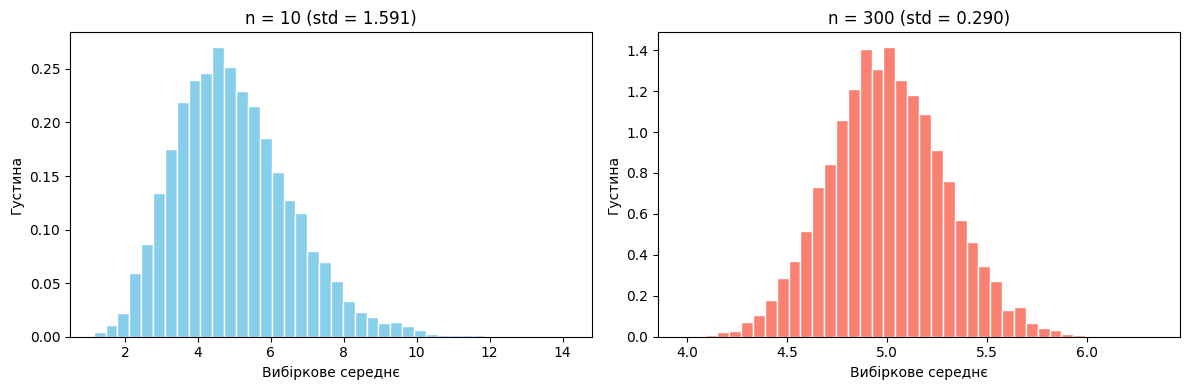

In [61]:
import matplotlib.pyplot as plt

n_repeats = 10_000

# Генерація матриць та обчислення середніх по рядках (axis=1)
means_n10 = rng.exponential(scale=1 / lam, size=(n_repeats, 10)).mean(axis=1)
means_n300 = rng.exponential(scale=1 / lam, size=(n_repeats, 300)).mean(axis=1)

# Побудова графіків
fig, axes = plt.subplots(1, 2 , figsize=(12, 4))

axes[0].hist(means_n10, bins=40, density=True, edgecolor="white", color="skyblue")
axes[0].set_title(f"n = 10 (std = {means_n10.std():.3f})")
axes[0].set_xlabel("Вибіркове середнє")
axes[0].set_ylabel("Густина")

axes[1].hist(means_n300, bins=40, density=True, edgecolor="white", color="salmon")
axes[1].set_title(f"n = 300 (std = {means_n300.std():.3f})")
axes[1].set_xlabel("Вибіркове середнє")
axes[1].set_ylabel("Густина")

plt.tight_layout()
plt.show()

In [62]:
import pandas as pd

n_values = [10, 30, 100, 300]
results = []

sigma = 1 / lam  # Для експоненційного розподілу стандартне відхилення дорівнює 1/λ = 5.0

for n in n_values:
    # Теоретична SE
    se_theory = sigma / np.sqrt(n)

    # Виміряна SE симуляцією
    simulated_means = rng.exponential(scale=sigma, size=(10_000, n)).mean(axis=1)
    se_simulated = simulated_means.std(ddof=1)

    results.append({
        "n": n,
        "Теоретична SE": round(se_theory, 4),
        "Виміряна SE (симуляція)": round(se_simulated, 4)
    })

df_se = pd.DataFrame(results)
display(df_se)

,n,Теоретична SE,Виміряна SE (симуляція)
0,10,1.5811,1.5970
1,30,0.9129,0.9042
2,100,0.5000,0.4999
3,300,0.2887,0.2875


In [66]:
se_25 = (1 / lam) / np.sqrt(25)
se_100 = (1 / lam) / np.sqrt(100)

print(f"SE для n = 25: {se_25:.4f}")
print(f"SE для n = 100: {se_100:.4f}")
print(f"відношення SE(25) / SE(100): {se_25 / se_100:.2f}")

SE для n = 25: 1.0000
SE для n = 100: 0.5000
відношення SE(25) / SE(100): 2.00


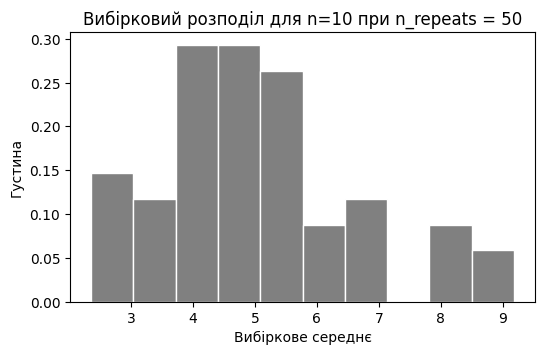

In [67]:
# Повторення для n = 10, але з n_repeats = 50
means_n10_small = rng.exponential(scale=1 / lam, size=(50, 10)).mean(axis=1)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(means_n10_small, bins=10, density=True, edgecolor="white", color="gray")
ax.set_title("Вибірковий розподіл для n=10 при n_repeats = 50")
ax.set_xlabel("Вибіркове середнє")
ax.set_ylabel("Густина")
plt.show()

### Відповіді на контрольні запитання:

1. **Відмінність між Законом великих чисел (ЗВЧ) та Центральною граничною теоремою (ЦГТ):**
   - Закон великих чисел відповідає на питання **«куди прямує вибіркове середнє $\bar{x}$»** зі зростанням розміру вибірки (воно збігається до істинного математичного сподівання $E[X]$).
   - Центральна гранична теорема відповідає на питання **«яку форму і який розкид має розподіл вибіркового середнього $\bar{x}$»** (розподіл $\bar{x}$ стає нормальним/дзвоноподібним із заданою стандартною похибкою незалежно від форми вихідного розподілу).

2. **Чому вихідний розподіл часу очікування обрано сильно скошеним (експоненційним):**
   - Вибір скошеного розподілу дозволяє наочно продемонструвати всю потужність ЦГТ: навіть коли самі вихідні дані катастрофічно далекі від нормального закону (мають асиметрію), їхні середні значення при великих $n$ все одно формують гарний симетричний нормальний дзвін.

3. **Чому стандартна похибка зменшується пропорційно $\sqrt{n}$, а не $n$:**
   - Математична формула дисперсії вибіркового середнього містить ділення на $n$ ($\sigma^2 / n$), тому при переході до середнього квадратичного відхилення (стандартної похибки) виникадіє квадратний корінь ($\sigma / \sqrt{n}$). Практично це означає, що для досягнення вищої точності (зниження похибки вдвічі) потрібно збирати не вдвічі, а вчетверо більше даних.